In [74]:
#import libaries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [75]:
#Load excel  file (dataset)
df = pd.read_excel(
    "../data/ai-exposure-categories.xlsx",
    sheet_name="AI Exposure Categories",
    header=1
)

# Display the first five rows
df.head()


,2025 National Employment Matrix title,2025 National Employment Matrix code,"Employment, 2025","Employment, 2035","Employment change, numeric, 2025–35","Employment change, percent, 2025–35","Percent self-employed, 2025","Occupational openings, 2025–35, annual average","Median annual wage, dollars, 2025",Typical education needed for entry,Work experience in a related occupation,Typical on-the-job training needed to attain competency in the occupation,Relative AI exposure
0,Chief executives,11-1011,291.6,300.9,9.3,3.2,26.6,19.1,213990,Bachelor's degree,5 years or more,NaN,Very high
1,General and operations managers,11-1021,3599.0,3780.3,181.3,5.0,0.8,285.0,105770,Bachelor's degree,5 years or more,NaN,High
2,Advertising and promotions managers,11-2011,33.2,31.9,-1.2,-3.7,35.1,2.3,133660,Bachelor's degree,Less than 5 years,NaN,Very high
3,Marketing managers,11-2021,421.6,450.8,29.1,6.9,5.3,34.0,166790,Bachelor's degree,5 years or more,NaN,Very high
4,Sales managers,11-2022,650.1,679.1,29.0,4.5,0.8,47.3,148270,Bachelor's degree,Less than 5 years,NaN,High


In [76]:
#Clean the dataset

# Remove rows that do not have an occupation code
df = df.dropna(
    subset=["2025 National Employment Matrix code"]
)

# Check the number of rows and columns
print("Dataset size:", df.shape)

# Check column names
print(df.columns.tolist())

# Check for missing values
print(df.isnull().sum())


Dataset size: (831, 13)
['2025 National Employment Matrix title', '2025 National Employment Matrix code', 'Employment, 2025', 'Employment, 2035', 'Employment change, numeric, 2025–35', 'Employment change, percent, 2025–35', 'Percent self-employed, 2025', 'Occupational openings, 2025–35, annual average', 'Median annual wage, dollars, 2025', 'Typical education needed for entry', 'Work experience in a related occupation', 'Typical on-the-job training needed to attain competency in the occupation', 'Relative AI exposure']
2025 National Employment Matrix title                                          0
2025 National Employment Matrix code                                           0
Employment, 2025                                                               0
Employment, 2035                                                               0
Employment change, numeric, 2025–35                                            0
Employment change, percent, 2025–35                                    

In [77]:
#Convert the numberical columns to numeric data types

# Columns that should contain numerical values
numeric_columns = [
    "Employment, 2025",
    "Employment, 2035",
    "Employment change, percent, 2025–35",
    "Percent self-employed, 2025",
    "Occupational openings, 2025–35, annual average",
    "Median annual wage, dollars, 2025"
]

# Convert columns to numerical values
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Check the updated data types
print(df[numeric_columns].dtypes)


Employment, 2025                                  float64
Employment, 2035                                  float64
Employment change, percent, 2025–35               float64
Percent self-employed, 2025                       float64
Occupational openings, 2025–35, annual average    float64
Median annual wage, dollars, 2025                 float64
dtype: object


Relative AI exposure
Low          213
Very high    206
High         206
Moderate     206
Name: count, dtype: int64


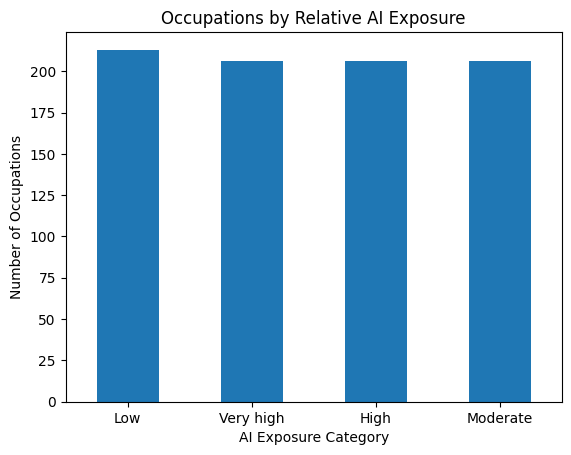

In [78]:
#Examine AI exposure categories

# Count occupations in each AI exposure category
exposure_counts = df["Relative AI exposure"].value_counts()

print(exposure_counts)

# Create a bar chart
exposure_counts.plot(kind="bar")

plt.title("Occupations by Relative AI Exposure")
plt.xlabel("AI Exposure Category")
plt.ylabel("Number of Occupations")
plt.xticks(rotation=0)
plt.show()


In [79]:
numerical_columns = [
    "Employment, 2025",
    "Employment change, percent, 2025–35",
    "Percent self-employed, 2025",
    "Occupational openings, 2025–35, annual average",
    "Median annual wage, dollars, 2025"
]

df[numerical_columns].describe()

,"Employment, 2025","Employment change, percent, 2025–35","Percent self-employed, 2025","Occupational openings, 2025–35, annual average","Median annual wage, dollars, 2025"
count,831.000000,831.000000,634.000000,831.000000,825.000000
mean,204.894344,2.077016,9.568454,21.011673,75010.848485
std,470.944336,7.240423,15.703852,61.723934,52548.781281
min,0.200000,-34.400000,0.000000,0.000000,30890.000000
25%,16.500000,-0.400000,0.900000,1.350000,47120.000000
50%,50.400000,2.700000,2.850000,4.100000,61390.000000
75%,164.000000,5.500000,9.775000,14.050000,81490.000000
max,4677.100000,41.000000,94.600000,827.400000,559030.000000


In [80]:
# Check missing values
df[numerical_columns].isnull().sum()

Employment, 2025                                    0
Employment change, percent, 2025–35                 0
Percent self-employed, 2025                       197
Occupational openings, 2025–35, annual average      0
Median annual wage, dollars, 2025                   6
dtype: int64

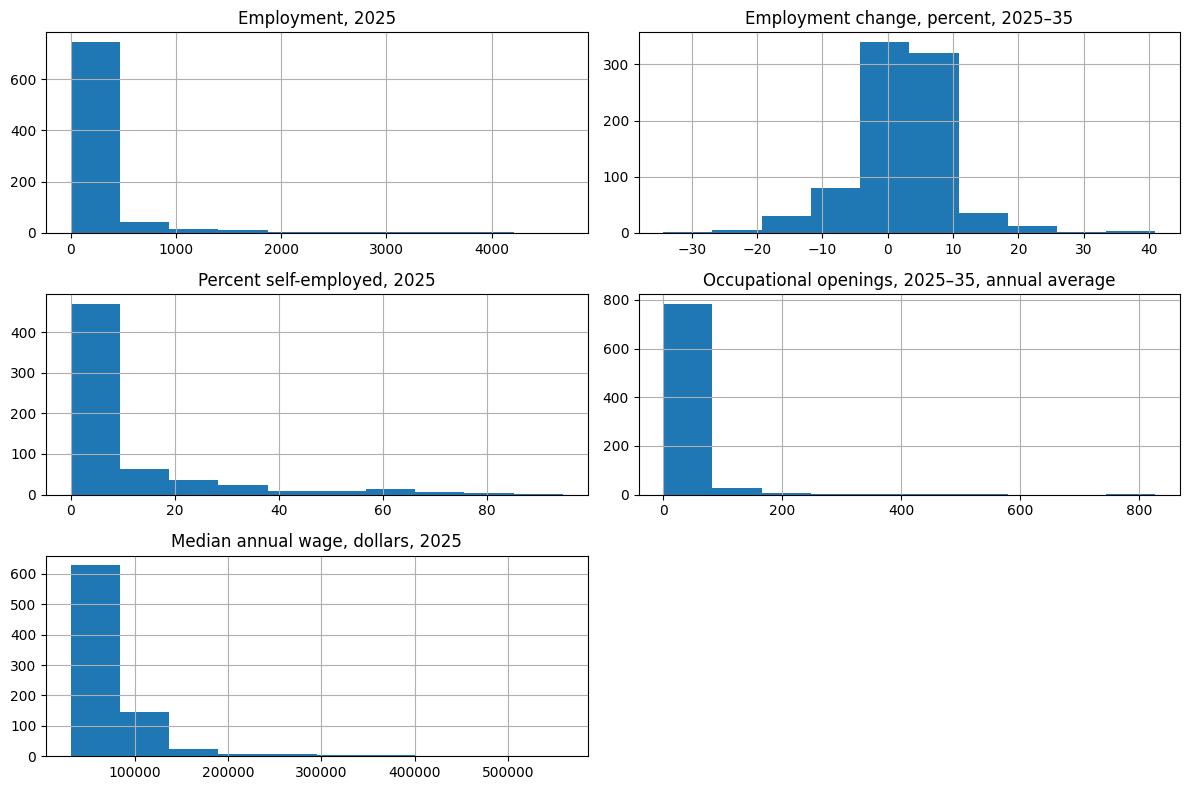

In [81]:
#create histograms before clustering
df[numerical_columns].hist(figsize=(12, 8))

plt.tight_layout()
plt.show()

In [82]:
#Clean and transform the data for clustering (remove any missing values and standardize the numerical columns)
import numpy as np

# Select the clustering features
features = [
    "Employment, 2025",
    "Employment change, percent, 2025–35",
    "Percent self-employed, 2025",
    "Occupational openings, 2025–35, annual average",
    "Median annual wage, dollars, 2025"
]

# Create a copy of the selected data
cluster_data = df[features].copy()

# Remove rows with missing wages
cluster_data = cluster_data.dropna(
    subset=["Median annual wage, dollars, 2025"]
)

# Replace missing self-employment values with the median
cluster_data["Percent self-employed, 2025"] = (
    cluster_data["Percent self-employed, 2025"].fillna(
        cluster_data["Percent self-employed, 2025"].median()
    )
)

# Apply log transformations
cluster_data["Employment, 2025"] = np.log1p(
    cluster_data["Employment, 2025"]
)

cluster_data["Percent self-employed, 2025"] = np.log1p(
    cluster_data["Percent self-employed, 2025"]
)

cluster_data["Occupational openings, 2025–35, annual average"] = np.log1p(
    cluster_data["Occupational openings, 2025–35, annual average"]
)

# Check the cleaned dataset
print(cluster_data.shape)
print(cluster_data.isnull().sum())

(825, 5)
Employment, 2025                                  0
Employment change, percent, 2025–35               0
Percent self-employed, 2025                       0
Occupational openings, 2025–35, annual average    0
Median annual wage, dollars, 2025                 0
dtype: int64


In [83]:
#Standardize the data
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Standardize the data
scaled_data = scaler.fit_transform(cluster_data)

# Check the standardized data
print(scaled_data.shape)
print(scaled_data[:5])

(825, 5)
[[ 1.02622931  0.15378674  1.78875417  0.80263867  2.64636885]
 [ 2.60285975  0.40180292 -0.93471182  2.77878723  0.58569979]
 [-0.32218621 -0.79694198  2.05658583 -0.54204465  1.1167667 ]
 [ 1.25715655  0.66359778  0.31503945  1.21541289  1.74761096]
 [ 1.52867452  0.33290954 -0.93471182  1.45511897  1.39496273]]


In [84]:
#Test different numbers of clusters (k) and evaluate the clustering performance using inertia and silhouette scores
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(scaled_data)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(silhouette_score(scaled_data, labels))

print("Inertia:", inertia_values)
print("Silhouette scores:", silhouette_values)

Inertia: [2933.9889346487694, 2423.899948253501, 2024.6277910864565, 1723.889608640669, 1508.0893328007853, 1350.5031878983978, 1211.5798607803545, 1142.5819388325142, 1076.9388966949343]
Silhouette scores: [np.float64(0.28334632404807114), np.float64(0.30702041270448605), np.float64(0.2859394025608447), np.float64(0.2829836638024867), np.float64(0.2601196331864997), np.float64(0.27051184917402726), np.float64(0.27443247371739227), np.float64(0.27180068256454976), np.float64(0.2328046111446622)]


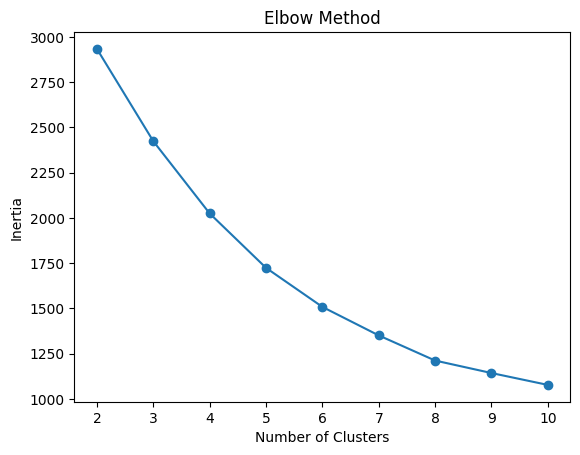

In [85]:
#Elbow chart
plt.plot(range(2, 11), inertia_values, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

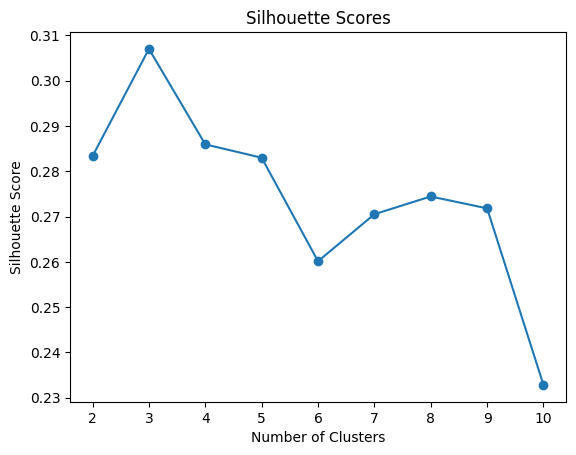

In [86]:
#Silhouette chart
plt.plot(range(2, 11), silhouette_values, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores")
plt.show()